<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/GaussianProcessDesign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Gaussian process to guide the experimental search for pectin extraction (Victor Z, UW-Madison, 2026).

| Slides | Python | Meaning |
|---|---|---|
| $\mathbf{x}$ | `x` | scaled temperature, time, acid concentration |
| $y$ | `y` | measured yields [%] |
| $m(\mathbf{x})$ | `m` | GP mean prediction |
| $\sigma(\mathbf{x})$ | `s` | GP standard deviation |
| $\max\; y(\mathbf{x})$ | `x_exploit` | exploitation: largest predicted yield |
| $\max\; \mathbb{V}[y(\mathbf{x})]$ | `x_explore` | exploration: largest uncertainty (information gain) |

**Note:** This notebook builds the GP model of the solvent-extraction example of the slides and uses it to search the design space for the highest predicted yield and for the largest information gain.

**The concept.** A Gaussian process (GP) models the unknown function as a random function: outputs at nearby inputs are correlated. The correlation is set by a kernel, here

$$k(\mathbf{x},\mathbf{x}')=c\,\exp\!\left(-\frac{\lVert\mathbf{x}-\mathbf{x}'\rVert^2}{2\ell^2}\right),$$

where $c$ sets the size of the variations and $\ell$ (length scale) sets how fast they happen. Given data $(\mathbf{X},\mathbf{y})$, conditioning the Gaussian gives the prediction at a new $\mathbf{x}$:

$$m(\mathbf{x})=\mathbf{k}(\mathbf{x})^T\mathbf{C}^{-1}\mathbf{y},\qquad \sigma^2(\mathbf{x})=k(\mathbf{x},\mathbf{x})-\mathbf{k}(\mathbf{x})^T\mathbf{C}^{-1}\mathbf{k}(\mathbf{x}),$$

with $\mathbf{C}_{ij}=k(\mathbf{x}_i,\mathbf{x}_j)+\alpha\,\delta_{ij}$ ($\alpha$ is the noise variance) and $\mathbf{k}(\mathbf{x})=(k(\mathbf{x},\mathbf{x}_1),\dots,k(\mathbf{x},\mathbf{x}_S))$. The second term of $\sigma^2$ is the uncertainty removed by the data: it is large near the experiments and vanishes far from them.

The next experiment can **exploit** the model, $\max_{\mathbf{x}}m(\mathbf{x})$, or **explore**, $\max_{\mathbf{x}}\sigma(\mathbf{x})$. We search over a discretized design space: 11 points per input, $11^3=1331$ conditions.

kernel: 1.71**2 * RBF(length_scale=2.17)
R^2 = 0.999


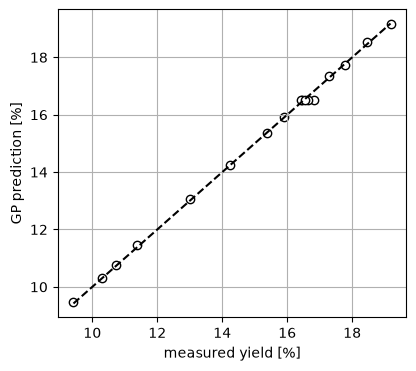

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

D = np.loadtxt(path + "Data/box_behnken.dat")
x, y = D[:, :3], D[:, 3]

gp = GaussianProcessRegressor(kernel=ConstantKernel(1.0, (1e-2, 1e3)) * RBF(1.0, (1e-2, 1e2)), normalize_y=True,
                              alpha=0.01, n_restarts_optimizer=10, random_state=0)
gp.fit(x, y)
print("kernel:", gp.kernel_)
y_hat = gp.predict(x)
R2 = 1 - np.sum((y - y_hat)**2) / np.sum((y - y.mean())**2)
print(f"R^2 = {R2:.3f}")

plt.figure(figsize=(4.5, 4))
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--")
plt.scatter(y, y_hat, facecolors="w", edgecolors="k")
plt.xlabel("measured yield [%]"); plt.ylabel("GP prediction [%]")
plt.grid(True); plt.show()

**The math, from scratch.** The library scales the outputs to zero mean and unit variance, $\tilde{\mathbf{y}}=(\mathbf{y}-\bar{y})/s_y$, finds $c$ and $\ell$ by maximum likelihood,

$$\log f(\tilde{\mathbf{y}})=-\tfrac{1}{2}\tilde{\mathbf{y}}^T\mathbf{C}^{-1}\tilde{\mathbf{y}}-\tfrac{1}{2}\log\mathrm{Det}(\mathbf{C})-\tfrac{S}{2}\log 2\pi,$$

and applies the formulas of $m(\mathbf{x})$ and $\sigma(\mathbf{x})$. We repeat them with linear algebra and compare.

In [3]:
c, ell = gp.kernel_.k1.constant_value, gp.kernel_.k2.length_scale
def k(A, B):
    d2 = ((A[:, None, :] - B[None, :, :])**2).sum(axis=2)       # squared distances
    return c * np.exp(-d2 / (2 * ell**2))

y_bar, s_y = y.mean(), y.std()
y_t = (y - y_bar) / s_y
C = k(x, x) + 0.01 * np.eye(len(y))                             # alpha = 0.01

def gp_predict(x_new):
    kx = k(x_new, x)                                            # one row k(x)^T per new point
    m = kx @ np.linalg.solve(C, y_t)
    v = c - np.sum(kx * np.linalg.solve(C, kx.T).T, axis=1)     # sigma^2(x)
    return y_bar + s_y * m, s_y * np.sqrt(v)                    # back to yield [%]

_, logdet = np.linalg.slogdet(C)
logf = -0.5 * y_t @ np.linalg.solve(C, y_t) - 0.5 * logdet - len(y) / 2 * np.log(2 * np.pi)
x_try = np.array([[0.2, -0.4, 0.6], [1.0, 1.0, 1.0]])
print("from scratch: m, s =", *(np.round(v, 4) for v in gp_predict(x_try)), f" log-likelihood = {logf:.4f}")
print("scikit-learn: m, s =", *(np.round(v, 4) for v in gp.predict(x_try, return_std=True)),
      f" log-likelihood = {gp.log_marginal_likelihood_value_:.4f}")

from scratch: m, s = [16.7017 18.3035] [0.2188 0.6026]  log-likelihood = -8.4587
scikit-learn: m, s = [16.7017 18.3035] [0.2188 0.6026]  log-likelihood = -8.4587


Predict the mean and the uncertainty on a grid of the design space.

In [4]:
g = np.linspace(-1, 1, 11)
grid = np.array(np.meshgrid(g, g, g, indexing="ij")).reshape(3, -1).T
m, s = gp.predict(grid, return_std=True)

def physical(x):
    """Scaled conditions to temperature [C], time [h], acid concentration [%]."""
    return np.array([85, 1.5, 0.2]) + np.asarray(x) * np.array([15, 0.5, 0.1])

x_exploit, x_explore = grid[np.argmax(m)], grid[np.argmax(s)]
print(f"exploit: x = {np.round(x_exploit, 2)}, physical {np.round(physical(x_exploit), 3)}: "
      f"m = {m.max():.2f} %, s = {s[np.argmax(m)]:.2f} %")
print(f"explore: x = {np.round(x_explore, 2)}, physical {np.round(physical(x_explore), 3)}: "
      f"m = {m[np.argmax(s)]:.2f} %, s = {s.max():.2f} %")
print(f"best measured yield = {y.max():.2f} %")

exploit: x = [1.  0.4 0.2], physical [100.     1.7    0.22]: m = 19.60 %, s = 0.28 %
explore: x = [-1.  1.  1.], physical [70.   2.   0.3]: m = 11.23 %, s = 0.60 %
best measured yield = 19.18 %


Predicted yield (top) and its uncertainty (bottom) on slices of the design space at three
temperatures; squares are the experiments on each slice, and stars mark the conditions of maximum
yield and maximum uncertainty.

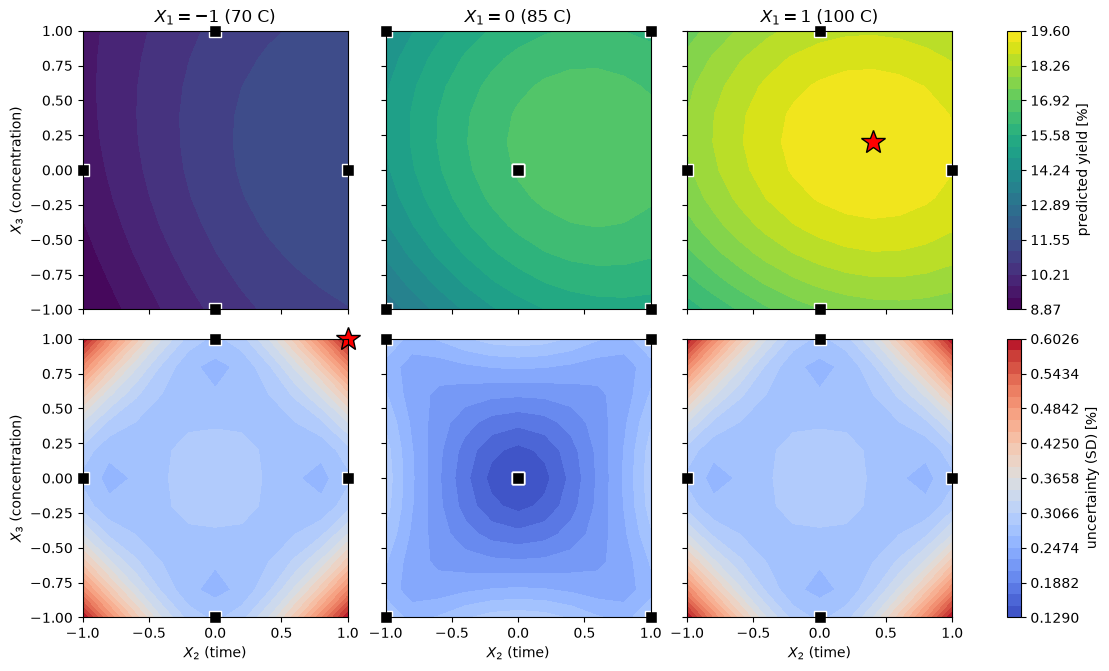

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6.6), sharex=True, sharey=True, constrained_layout=True)
for r, (v, star, cmap, lab) in enumerate([(m, x_exploit, "viridis", "predicted yield [%]"),
                                          (s, x_explore, "coolwarm", "uncertainty (SD) [%]")]):
    levels = np.linspace(v.min(), v.max(), 25)
    for k, T in enumerate([-1, 0, 1]):
        V = v[grid[:, 0] == T].reshape(11, 11)             # rows: time, columns: concentration
        im = axs[r, k].contourf(g, g, V.T, levels=levels, cmap=cmap)
        on = x[:, 0] == T
        axs[r, k].plot(x[on, 1], x[on, 2], "ks", mec="w", ms=8, clip_on=False)
        if star[0] == T:
            axs[r, k].plot(star[1], star[2], "r*", mec="k", ms=18, clip_on=False)
        axs[0, k].set_title(f"$X_1={T}$ ({85 + 15*T} C)")
        axs[1, k].set_xlabel("$X_2$ (time)")
    axs[r, 0].set_ylabel("$X_3$ (concentration)")
    fig.colorbar(im, ax=axs[r, :], label=lab)
plt.show()

**The whole design space in 3D.** Each dot is a condition of a coarser mesh (6 points per input, every other point of the grid), colored by performance (left) and by uncertainty (right). Black squares are the experiments; the stars are the best predicted conditions and the most uncertain conditions.

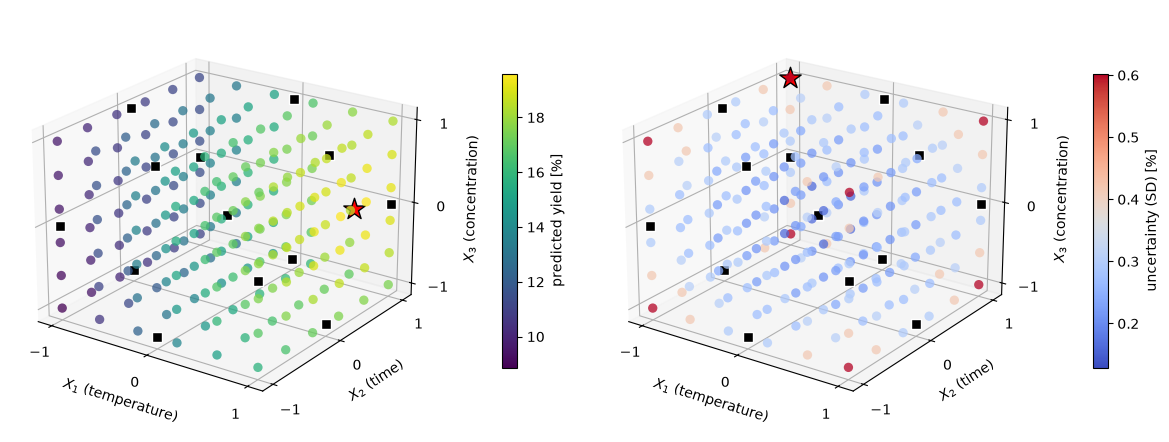

In [6]:
coarse = np.isin(np.round(grid, 6), np.round(g[::2], 6)).all(axis=1)     # 6 x 6 x 6 = 216 points
fig = plt.figure(figsize=(12, 5.2))
for j, (v, star, cm, lab) in enumerate([(m, x_exploit, "viridis", "predicted yield [%]"),
                                        (s, x_explore, "coolwarm", "uncertainty (SD) [%]")]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    im = ax.scatter(*grid[coarse].T, c=v[coarse], cmap=cm, s=45, alpha=0.75, linewidths=0, depthshade=False, vmin=v.min(), vmax=v.max())
    ax.scatter(*x.T, color="k", marker="s", s=45, edgecolors="w", depthshade=False)
    ax.scatter(*star, color="red", marker="*", s=260, edgecolors="k", depthshade=False)
    ax.set_xlabel("$X_1$ (temperature)"); ax.set_ylabel("$X_2$ (time)"); ax.set_zlabel("$X_3$ (concentration)")
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
    ax.view_init(elev=22, azim=-55)
    cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.12, label=lab)
    cb.solids.set_alpha(1)
fig.tight_layout()
plt.show()

The experiments of largest information gain, in order of uncertainty:

In [7]:
top = np.argsort(s, kind="stable")[::-1][:10]
print(pd.DataFrame(np.column_stack([physical(grid[top]), m[top], s[top]]),
                   columns=["T [C]", "time [h]", "conc [%]", "m [%]", "s [%]"]).round(2).to_string())

   T [C]  time [h]  conc [%]  m [%]  s [%]
0   70.0       2.0      0.30  11.23    0.6
1  100.0       1.0      0.10  15.78    0.6
2  100.0       2.0      0.10  17.50    0.6
3   70.0       1.0      0.30   9.59    0.6
4  100.0       2.0      0.30  18.30    0.6
5   70.0       2.0      0.10  11.09    0.6
6   70.0       1.0      0.10   8.87    0.6
7  100.0       1.0      0.30  17.17    0.6
8  100.0       1.0      0.12  16.33    0.5
9  100.0       2.0      0.12  18.00    0.5


**Note:** The GP interpolates the data and flags the regions it has not seen: the corners of the cube, where the Box-Behnken design has no experiments, have the largest uncertainty. Exploitation suggests high temperature; exploration suggests a corner.